In [1]:
print("Ядро Python работает!")

Ядро Python работает!


In [2]:
from pathlib import Path

data_path = Path("../data/cookie_cats.csv")

print("Файл найден:", data_path.exists())
print("Путь к файлу:", data_path.resolve())

Файл найден: True
Путь к файлу: C:\Users\Админ\Desktop\product_analytics_ab_test\Data\cookie_cats.csv


In [3]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/cookie_cats.csv")

print("Файл найден:", data_path.exists())
print("Путь к файлу:", data_path.resolve())

Файл найден: True
Путь к файлу: C:\Users\Админ\Desktop\product_analytics_ab_test\Data\cookie_cats.csv


In [4]:
df = pd.read_csv(data_path)

print("Количество строк и столбцов:", df.shape)
print("\nНазвания столбцов:")
print(df.columns.tolist())

df.head()

Количество строк и столбцов: (90189, 5)

Названия столбцов:
['userid', 'version', 'sum_gamerounds', 'retention_1', 'retention_7']


,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


In [5]:
# Размер датасета
print("Размер таблицы:", df.shape)

# Типы данных и пропуски
df.info()

# Количество пропусков в каждом столбце
print("\nПропуски:")
print(df.isna().sum())

# Количество уникальных игроков
print("\nУникальных игроков:", df["userid"].nunique())

# Проверка дубликатов
print("Дубликатов строк:", df.duplicated().sum())
print("Повторяющихся ID игроков:", df["userid"].duplicated().sum())

Размер таблицы: (90189, 5)
<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB

Пропуски:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64

Уникальных игроков: 90189
Дубликатов строк: 0
Повторяющихся ID игроков: 0


In [6]:
# Количество игроков в каждой группе
print("Размер групп:")
print(df["version"].value_counts())

# Доли групп в процентах
print("\nДоли групп:")
print((df["version"].value_counts(normalize=True) * 100).round(2))

# Проверяем, какие значения есть в столбце version
print("\nНазвания групп:")
print(df["version"].unique())

# Проверяем минимальное и максимальное количество раундов
print("\nСтатистика игровых раундов:")
print(df["sum_gamerounds"].describe())

Размер групп:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Доли групп:
version
gate_40    50.44
gate_30    49.56
Name: proportion, dtype: float64

Названия групп:
<StringArray>
['gate_30', 'gate_40']
Length: 2, dtype: str

Статистика игровых раундов:
count    90189.000000
mean        51.872457
std        195.050858
min          0.000000
25%          5.000000
50%         16.000000
75%         51.000000
max      49854.000000
Name: sum_gamerounds, dtype: float64


In [7]:
from scipy.stats import binomtest

n_control = (df["version"] == "gate_30").sum()
n_test = (df["version"] == "gate_40").sum()
n_total = len(df)

result = binomtest(
    k=n_test,
    n=n_total,
    p=0.5,
    alternative="two-sided"
)

print(f"Контрольная группа: {n_control} ({n_control / n_total:.2%})")
print(f"Тестовая группа: {n_test} ({n_test / n_total:.2%})")
print(f"Ожидаемое количество на группу: {n_total / 2:.0f}")
print(f"SRM p-value: {result.pvalue:.5f}")

Контрольная группа: 44700 (49.56%)
Тестовая группа: 45489 (50.44%)
Ожидаемое количество на группу: 45094
SRM p-value: 0.00869


In [8]:
expected = len(df) / 2

for group in ["gate_30", "gate_40"]:
    actual = (df["version"] == group).sum()
    difference = actual - expected
    relative_difference = difference / expected * 100

    print(f"\nГруппа: {group}")
    print(f"Фактически: {actual}")
    print(f"Ожидалось: {expected:.0f}")
    print(f"Отклонение: {difference:+.1f} игроков")
    print(f"Относительное отклонение: {relative_difference:+.3f}%")


Группа: gate_30
Фактически: 44700
Ожидалось: 45094
Отклонение: -394.5 игроков
Относительное отклонение: -0.875%

Группа: gate_40
Фактически: 45489
Ожидалось: 45094
Отклонение: +394.5 игроков
Относительное отклонение: +0.875%


In [9]:
# Самые большие значения
print("Топ-10 игроков по количеству раундов:")
display(
    df.nlargest(10, "sum_gamerounds")[
        ["userid", "version", "sum_gamerounds", "retention_1", "retention_7"]
    ]
)

# Количество игроков с большим числом раундов
for threshold in [100, 500, 1000, 10000]:
    count = (df["sum_gamerounds"] > threshold).sum()
    print(f"Игроков с раундами > {threshold}: {count}")

# Игроки, которые не сыграли ни одного раунда
print(
    "\nИгроков с 0 раундов:",
    (df["sum_gamerounds"] == 0).sum()
)

Топ-10 игроков по количеству раундов:


,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True
46344,5133952,gate_30,2251,True,True
87007,9640085,gate_30,2156,True,True
36933,4090246,gate_40,2124,True,True
88328,9791599,gate_40,2063,True,True
6536,725080,gate_40,2015,True,True


Игроков с раундами > 100: 12385
Игроков с раундами > 500: 856
Игроков с раундами > 1000: 116
Игроков с раундами > 10000: 1

Игроков с 0 раундов: 3994


In [10]:
engagement = df.groupby("version")["sum_gamerounds"].agg(
    ["count", "mean", "median", "std", "min", "max"]
).round(2)

display(engagement)

,count,mean,median,std,min,max
version,,,,,,
gate_30,44700,52.46,17.0,256.72,0,49854
gate_40,45489,51.30,16.0,103.29,0,2640


In [11]:
df_without_extreme = df[df["sum_gamerounds"] < 10000]

comparison = pd.DataFrame({
    "Все данные": df.groupby("version")["sum_gamerounds"].mean(),
    "Без значений >= 10000": (
        df_without_extreme.groupby("version")["sum_gamerounds"].mean()
    )
}).round(2)

display(comparison)

,Все данные,Без значений >= 10000
version,,
gate_30,52.46,51.34
gate_40,51.30,51.30


In [12]:
retention = df.groupby("version").agg(
    users=("userid", "nunique"),
    d1_retained=("retention_1", "sum"),
    d7_retained=("retention_7", "sum")
)

retention["D1_retention"] = (
    retention["d1_retained"] / retention["users"] * 100
)

retention["D7_retention"] = (
    retention["d7_retained"] / retention["users"] * 100
)

display(retention.round(2))

,users,d1_retained,d7_retained,D1_retention,D7_retention
version,,,,,
gate_30,44700,20034,8502,44.82,19.02
gate_40,45489,20119,8279,44.23,18.20


In [13]:
d1_diff = (
    retention.loc["gate_40", "D1_retention"]
    - retention.loc["gate_30", "D1_retention"]
)

d7_diff = (
    retention.loc["gate_40", "D7_retention"]
    - retention.loc["gate_30", "D7_retention"]
)

print(f"Разница D1: {d1_diff:+.2f} процентного пункта")
print(f"Разница D7: {d7_diff:+.2f} процентного пункта")

Разница D1: -0.59 процентного пункта
Разница D7: -0.82 процентного пункта


In [14]:
import numpy as np
from scipy.stats import norm

def compare_proportions(success_control, n_control,
                        success_test, n_test):
    p_control = success_control / n_control
    p_test = success_test / n_test

    # Z-тест двух долей
    pooled = (success_control + success_test) / (n_control + n_test)

    se_test = np.sqrt(
        pooled * (1 - pooled) * (1 / n_control + 1 / n_test)
    )

    z_score = (p_test - p_control) / se_test
    p_value = 2 * norm.sf(abs(z_score))

    # Приближённый 95% доверительный интервал разницы
    se_diff = np.sqrt(
        p_control * (1 - p_control) / n_control
        + p_test * (1 - p_test) / n_test
    )

    difference = p_test - p_control
    ci_low = difference - 1.96 * se_diff
    ci_high = difference + 1.96 * se_diff

    return {
        "control": p_control * 100,
        "test": p_test * 100,
        "difference_pp": difference * 100,
        "ci_low_pp": ci_low * 100,
        "ci_high_pp": ci_high * 100,
        "p_value": p_value
    }


n_control = (df["version"] == "gate_30").sum()
n_test = (df["version"] == "gate_40").sum()

for metric in ["retention_1", "retention_7"]:
    control_success = df.loc[
        df["version"] == "gate_30", metric
    ].sum()

    test_success = df.loc[
        df["version"] == "gate_40", metric
    ].sum()

    result = compare_proportions(
        control_success, n_control,
        test_success, n_test
    )

    print(f"\nМетрика: {metric}")
    for key, value in result.items():
        print(f"{key}: {value:.5f}")


Метрика: retention_1
control: 44.81879
test: 44.22827
difference_pp: -0.59052
ci_low_pp: -1.23926
ci_high_pp: 0.05822
p_value: 0.07441

Метрика: retention_7
control: 19.02013
test: 18.20000
difference_pp: -0.82013
ci_low_pp: -1.32816
ci_high_pp: -0.31210
p_value: 0.00155


In [15]:
# Исходный результат D7
d7_original = df.groupby("version")["retention_7"].mean() * 100

# Чувствительность: исключаем игроков с >= 10000 раундов
df_sensitivity = df[df["sum_gamerounds"] < 10000]
d7_sensitivity = (
    df_sensitivity.groupby("version")["retention_7"].mean() * 100
)

print("D7 retention — все данные:")
print(d7_original.round(4))

print("\nD7 retention — без игроков с >= 10000 раундов:")
print(d7_sensitivity.round(4))

print("\nИзменение D7 после фильтрации, п. п.:")
print((d7_sensitivity - d7_original).round(6))

D7 retention — все данные:
version
gate_30    19.0201
gate_40    18.2000
Name: retention_7, dtype: float64

D7 retention — без игроков с >= 10000 раундов:
version
gate_30    19.0183
gate_40    18.2000
Name: retention_7, dtype: float64

Изменение D7 после фильтрации, п. п.:
version
gate_30   -0.001812
gate_40    0.000000
Name: retention_7, dtype: float64


In [16]:
from statsmodels.stats.multitest import multipletests

p_values = [0.07441, 0.00155]
metric_names = ["D1 retention", "D7 retention"]

rejected, corrected_p, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="bonferroni"
)

for name, p, p_adj, significant in zip(
    metric_names, p_values, corrected_p, rejected
):
    print(f"\n{name}")
    print(f"Исходный p-value: {p:.5f}")
    print(f"Скорректированный p-value: {p_adj:.5f}")
    print(f"Значимо после поправки: {'Да' if significant else 'Нет'}")

ModuleNotFoundError: No module named 'statsmodels'

In [ ]:
from statsmodels.stats.multitest import multipletests

p_values = [0.07441, 0.00155]
metric_names = ["D1 retention", "D7 retention"]

rejected, corrected_p, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="bonferroni"
)

for name, p, p_adj, significant in zip(
    metric_names, p_values, corrected_p, rejected
):
    print(f"\n{name}")
    print(f"Исходный p-value: {p:.5f}")
    print(f"Скорректированный p-value: {p_adj:.5f}")
    print(f"Значимо после поправки: {'Да' if significant else 'Нет'}")

In [1]:
from statsmodels.stats.multitest import multipletests

p_values = [0.07441, 0.00155]
metric_names = ["D1 retention", "D7 retention"]

rejected, corrected_p, _, _ = multipletests(
    p_values,
    alpha=0.05,
    method="bonferroni"
)

for name, p, p_adj, significant in zip(
    metric_names, p_values, corrected_p, rejected
):
    print(f"\n{name}")
    print(f"Исходный p-value: {p:.5f}")
    print(f"Скорректированный p-value: {p_adj:.5f}")
    print(f"Значимо после поправки: {'Да' if significant else 'Нет'}")


D1 retention
Исходный p-value: 0.07441
Скорректированный p-value: 0.14882
Значимо после поправки: Нет

D7 retention
Исходный p-value: 0.00155
Скорректированный p-value: 0.00310
Значимо после поправки: Да


In [2]:
import pandas as pd

df["player_segment"] = pd.cut(
    df["sum_gamerounds"],
    bins=[-1, 10, 50, float("inf")],
    labels=["Low activity", "Medium activity", "High activity"]
)

segment_analysis = df.groupby(
    ["player_segment", "version"],
    observed=False
).agg(
    users=("userid", "nunique"),
    avg_gamerounds=("sum_gamerounds", "mean"),
    d1_retention=("retention_1", "mean"),
    d7_retention=("retention_7", "mean")
).reset_index()

segment_analysis["d1_retention"] *= 100
segment_analysis["d7_retention"] *= 100

segment_analysis.round(2)

NameError: name 'df' is not defined

In [3]:
from pathlib import Path
import pandas as pd

data_path = Path("../data/cookie_cats.csv")
df = pd.read_csv(data_path)

print(df.shape)

(90189, 5)


In [4]:
import pandas as pd

df["player_segment"] = pd.cut(
    df["sum_gamerounds"],
    bins=[-1, 10, 50, float("inf")],
    labels=["Low activity", "Medium activity", "High activity"]
)

segment_analysis = df.groupby(
    ["player_segment", "version"],
    observed=False
).agg(
    users=("userid", "nunique"),
    avg_gamerounds=("sum_gamerounds", "mean"),
    d1_retention=("retention_1", "mean"),
    d7_retention=("retention_7", "mean")
).reset_index()

segment_analysis["d1_retention"] *= 100
segment_analysis["d7_retention"] *= 100

segment_analysis.round(2)

,player_segment,version,users,avg_gamerounds,d1_retention,d7_retention
0,Low activity,gate_30,17673,4.01,11.34,1.81
1,Low activity,gate_40,18316,3.97,11.34,1.79
2,Medium activity,gate_30,15891,25.52,53.09,12.03
3,Medium activity,gate_40,15497,24.80,52.31,10.81
4,High activity,gate_30,11136,167.77,86.14,56.31
5,High activity,gate_40,11676,160.71,85.10,53.74


In [5]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

results = []

for segment in ["Low activity", "Medium activity", "High activity"]:
    control = df[
        (df["player_segment"] == segment) &
        (df["version"] == "gate_30")
    ]["retention_7"]

    test = df[
        (df["player_segment"] == segment) &
        (df["version"] == "gate_40")
    ]["retention_7"]

    count = [test.sum(), control.sum()]
    nobs = [len(test), len(control)]

    _, p_value = proportions_ztest(count, nobs)

    results.append({
        "segment": segment,
        "D7_gate_30_%": control.mean() * 100,
        "D7_gate_40_%": test.mean() * 100,
        "difference_pp": (test.mean() - control.mean()) * 100,
        "p_value": p_value
    })

segment_results = pd.DataFrame(results)

segment_results["p_adjusted"] = multipletests(
    segment_results["p_value"],
    method="bonferroni"
)[1]

segment_results.round(4)

,segment,D7_gate_30_%,D7_gate_40_%,difference_pp,p_value,p_adjusted
0,Low activity,1.8107,1.7908,-0.0199,0.8872,1.0000
1,Medium activity,12.0257,10.8150,-1.2107,0.0007,0.0022
2,High activity,56.3129,53.7427,-2.5701,0.0001,0.0003


In [6]:
from scipy.stats import binomtest

n_control = (df["version"] == "gate_30").sum()
n_test = (df["version"] == "gate_40").sum()
n_total = n_control + n_test

srm_test = binomtest(
    n_test,
    n=n_total,
    p=0.5,
    alternative="two-sided"
)

print(f"Всего пользователей: {n_total:,}")
print(f"Контрольная группа: {n_control:,} ({n_control / n_total:.2%})")
print(f"Тестовая группа: {n_test:,} ({n_test / n_total:.2%})")
print(f"SRM p-value: {srm_test.pvalue:.5f}")

Всего пользователей: 90,189
Контрольная группа: 44,700 (49.56%)
Тестовая группа: 45,489 (50.44%)
SRM p-value: 0.00869


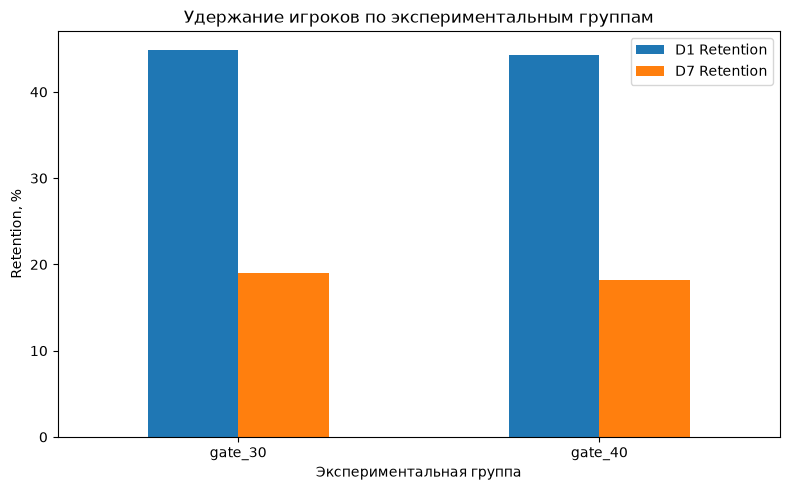

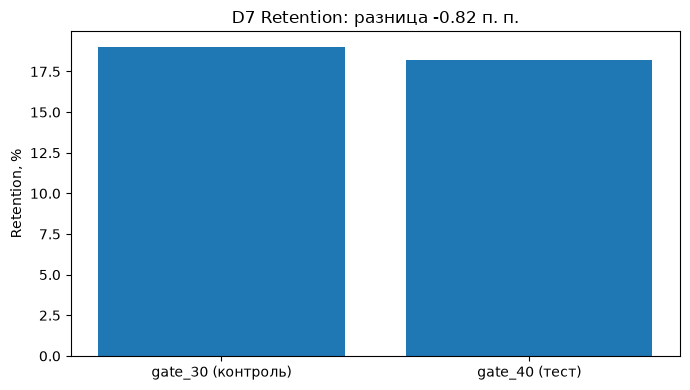

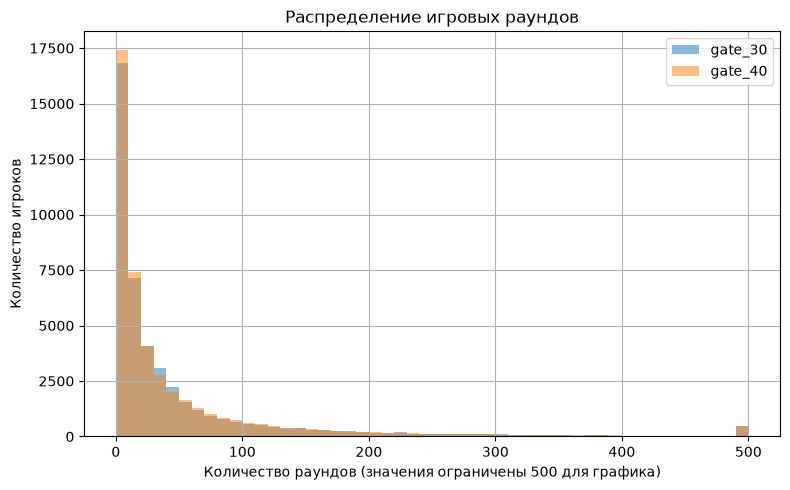

In [7]:
import matplotlib.pyplot as plt
import pandas as pd

# Подготовка метрик по группам
metrics = df.groupby("version").agg(
    users=("userid", "nunique"),
    D1_Retention=("retention_1", "mean"),
    D7_Retention=("retention_7", "mean")
)

metrics[["D1_Retention", "D7_Retention"]] *= 100

# График 1. Сравнение удержания
metrics[["D1_Retention", "D7_Retention"]].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Удержание игроков по экспериментальным группам")
plt.xlabel("Экспериментальная группа")
plt.ylabel("Retention, %")
plt.xticks(rotation=0)
plt.legend(["D1 Retention", "D7 Retention"])
plt.tight_layout()
plt.show()

# График 2. Разница D7 Retention
d7_control = metrics.loc["gate_30", "D7_Retention"]
d7_test = metrics.loc["gate_40", "D7_Retention"]
difference = d7_test - d7_control

plt.figure(figsize=(7, 4))
plt.bar(
    ["gate_30 (контроль)", "gate_40 (тест)"],
    [d7_control, d7_test]
)
plt.title(f"D7 Retention: разница {difference:.2f} п. п.")
plt.ylabel("Retention, %")
plt.tight_layout()
plt.show()

# График 3. Распределение количества раундов
plt.figure(figsize=(8, 5))

for version in ["gate_30", "gate_40"]:
    df.loc[df["version"] == version, "sum_gamerounds"].clip(upper=500).hist(
        bins=50,
        alpha=0.5,
        label=version
    )

plt.title("Распределение игровых раундов")
plt.xlabel("Количество раундов (значения ограничены 500 для графика)")
plt.ylabel("Количество игроков")
plt.legend()
plt.tight_layout()
plt.show()

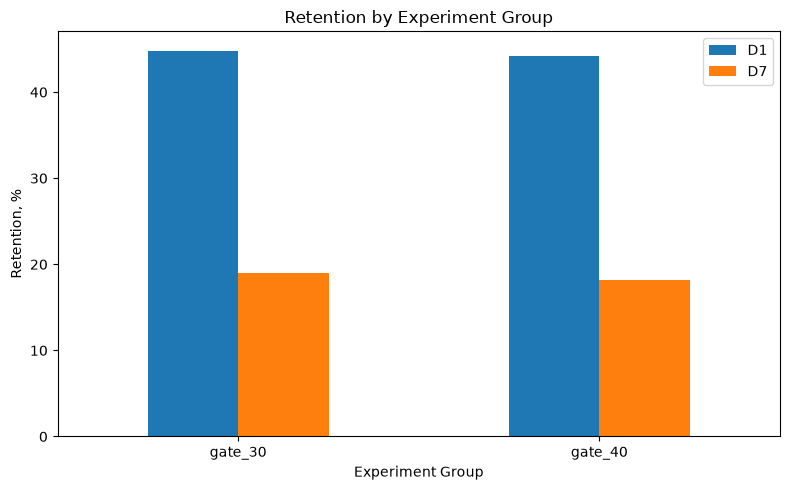

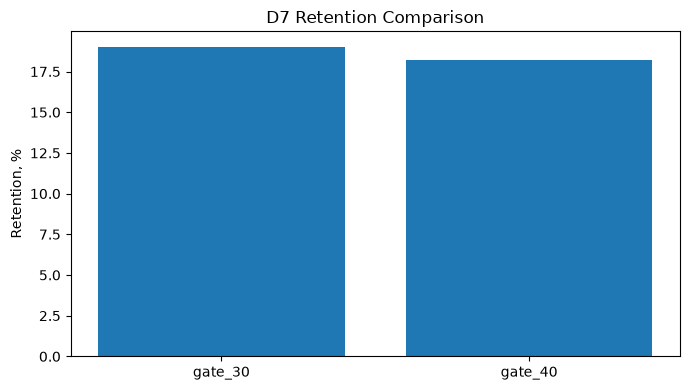

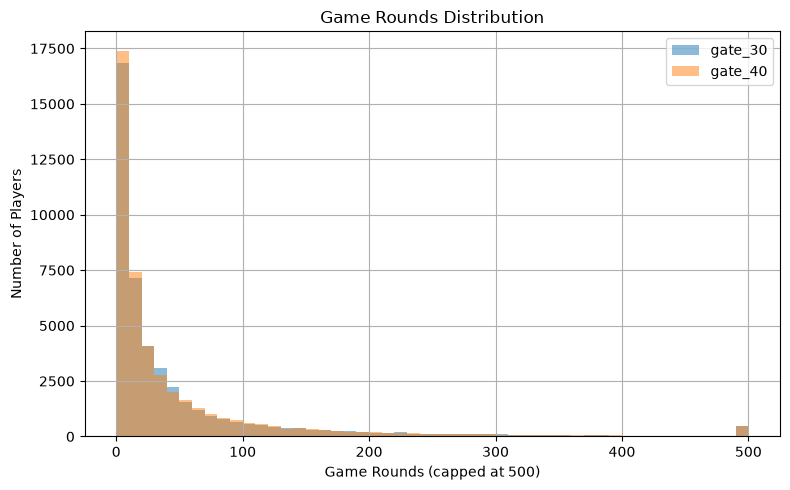

Готово! Файлы сохранены в: C:\Users\Админ\Desktop\product_analytics_ab_test\images
Содержимое папки: ['d7_retention.png', 'game_rounds_distribution.png', 'retention_comparison.png']


In [15]:

from pathlib import Path
import matplotlib.pyplot as plt

# Создаём папку для графиков
images_dir = Path("../images")
images_dir.mkdir(parents=True, exist_ok=True)

# Подготавливаем данные
metrics = df.groupby("version").agg(
    D1=("retention_1", "mean"),
    D7=("retention_7", "mean")
) * 100

# График 1: D1 и D7 Retention
ax = metrics[["D1", "D7"]].plot(
    kind="bar", figsize=(8, 5)
)
ax.set_title("Retention by Experiment Group")
ax.set_xlabel("Experiment Group")
ax.set_ylabel("Retention, %")
ax.set_xticklabels(metrics.index, rotation=0)
plt.tight_layout()
plt.savefig(images_dir / "retention_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# График 2: сравнение D7 Retention
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(
    ["gate_30", "gate_40"],
    [metrics.loc["gate_30", "D7"],
     metrics.loc["gate_40", "D7"]]
)
ax.set_title("D7 Retention Comparison")
ax.set_ylabel("Retention, %")
plt.tight_layout()
plt.savefig(images_dir / "d7_retention.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# График 3: распределение игровых раундов
fig, ax = plt.subplots(figsize=(8, 5))
for version in ["gate_30", "gate_40"]:
    df.loc[df["version"] == version, "sum_gamerounds"].clip(
        upper=500
    ).hist(bins=50, alpha=0.5, label=version, ax=ax)

ax.set_title("Game Rounds Distribution")
ax.set_xlabel("Game Rounds (capped at 500)")
ax.set_ylabel("Number of Players")
ax.legend()
plt.tight_layout()
plt.savefig(images_dir / "game_rounds_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()
plt.close()

print("Готово! Файлы сохранены в:", images_dir.resolve())
print("Содержимое папки:", [p.name for p in images_dir.glob("*.png")])


In [8]:
from pathlib import Path

images_dir = Path("../images")
images_dir.mkdir(parents=True, exist_ok=True)

print("Папка для графиков готова:", images_dir.resolve())

Папка для графиков готова: C:\Users\Админ\Desktop\product_analytics_ab_test\images


In [9]:
plt.tight_layout()
plt.savefig(images_dir / "retention_comparison.png", dpi=300, bbox_inches="tight")
plt.show()


<Figure size 640x480 with 0 Axes>

In [10]:
plt.tight_layout()
plt.savefig(images_dir / "d7_retention.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [11]:
plt.tight_layout()
plt.savefig(images_dir / "game_rounds_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

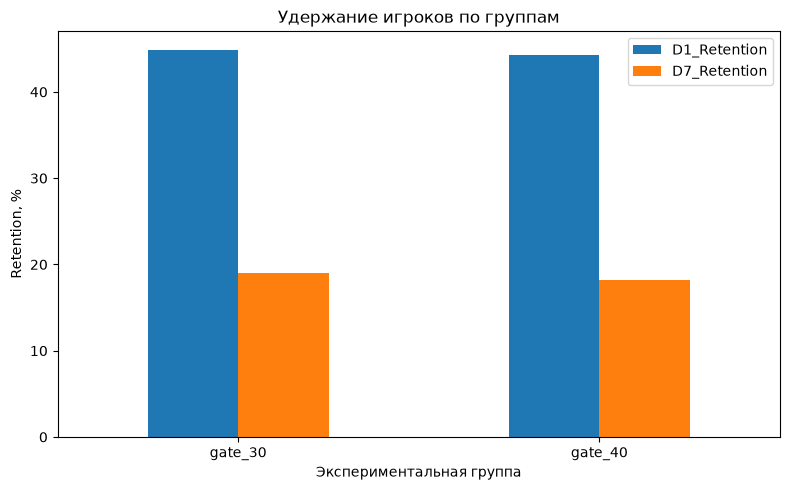

In [12]:
import matplotlib.pyplot as plt

metrics = df.groupby("version").agg(
    D1_Retention=("retention_1", "mean"),
    D7_Retention=("retention_7", "mean")
) * 100

metrics[["D1_Retention", "D7_Retention"]].plot(
    kind="bar", figsize=(8, 5)
)

plt.title("Удержание игроков по группам")
plt.xlabel("Экспериментальная группа")
plt.ylabel("Retention, %")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
from pathlib import Path

images_dir = Path("../images")
images_dir.mkdir(parents=True, exist_ok=True)

print("Папка готова:", images_dir.resolve())

Папка готова: C:\Users\Админ\Desktop\product_analytics_ab_test\images


In [14]:
plt.savefig(images_dir / "retention_comparison.png",
            dpi=300, bbox_inches="tight")

<Figure size 640x480 with 0 Axes>